## 1. Lấy dữ liệu VN30 từ SSI iBoard

In [1]:
import json, urllib.request
import numpy as np, pandas as pd
 
url = ("https://iboard-api.ssi.com.vn/statistics/charts/history"
       "?resolution=1D&symbol=VN30&from=1451606400&to=1767225599")
req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
d = json.load(urllib.request.urlopen(req))["data"]
 
df = pd.DataFrame({"date": pd.to_datetime(d["t"], unit="s").date,
                   "open": d["o"], "high": d["h"], "low": d["l"],
                   "close": d["c"], "volume": d["v"]})
df.to_csv("../data/raw/VN30_2016_2025.csv", index=False)
print(len(df))


2498


## 2. Kiểm tra và vẽ dữ liệu

In [2]:
#Đọc File
df = pd.read_csv("../data/raw/VN30_2016_2025.csv", parse_dates=["date"], index_col="date")
print(df.shape)                                  
print("Ô trống:", df.isna().sum().sum())          
print("high < low:", (df.high < df.low).sum())     
print(df.groupby(df.index.year).size())           # ~250 phiên mỗi năm

(2498, 5)
Ô trống: 0
high < low: 0
date
2016    251
2017    250
2018    248
2019    250
2020    252
2021    250
2022    249
2023    249
2024    250
2025    249
dtype: int64


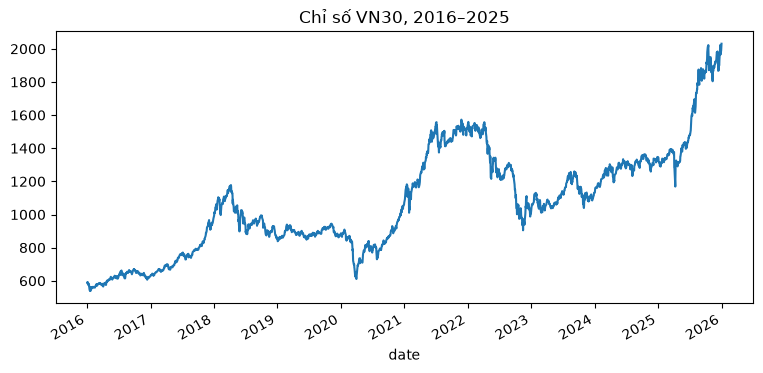

In [3]:
#Vẽ biểu đồ giá đóng cửa của chỉ số VN30 từ năm 2016 đến 2025
ax = df["close"].plot(figsize=(9, 4), title="Chỉ số VN30, 2016–2025")
ax.figure.savefig("../reports/figures/vn30_close.png", dpi=150)

## 3. Tạo nhãn Tăng/Giảm

In [4]:
#Mỗi phiên t có nhãn y_t = +1 nếu giá đóng cửa phiên sau cao hơn, ngược lại −1
df["y"] = np.where(df["close"].shift(-1) > df["close"], 1, -1)
df = df.iloc[:-1]          # phiên cuối chưa biết ngày mai → bỏ
print(df["y"].value_counts(normalize=True))


y
 1    0.561073
-1    0.438927
Name: proportion, dtype: float64
